# DS201 — Lab 2: Bài 3 và Bài 4

Họ tên: Nguyễn Thị Kim Ngân
MSSV: 24521130  
Lớp: DS201.R11.1



## A.1. Thư viện


In [1]:
import importlib.util
import subprocess
import sys

required = {"transformers": "transformers", "sklearn": "scikit-learn",
            "seaborn": "seaborn", "tqdm": "tqdm", "pandas": "pandas"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


## A.2. Cấu hình



In [2]:
import os
import gc
import time
import random
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, random_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
BATCH = 32
EPOCHS = 20
NUM_WORKERS = 2
RESUME = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_ROOT = Path("/kaggle/working/lab2_bai3_bai4") if Path("/kaggle").exists() else Path("outputs/lab2_bai3_bai4")
OUT_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS = {}

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in ps if p.requires_grad)
    return sum(p.numel() for p in ps)

def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

set_seed()
print("PyTorch:", torch.__version__, "| device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128 | device: cuda
GPU: Tesla T4


## A.3. Đường dẫn dữ liệu

Dữ liệu gồm `train/` và `test/`, mỗi tập có 21 thư mục lớp. Nếu gắn nhiều dataset, đặt đường dẫn cụ thể ở `DATA_ROOT_OVERRIDE`.


In [ ]:
DATA_ROOT_OVERRIDE = None  
if DATA_ROOT_OVERRIDE:
    DATA_ROOT = Path(DATA_ROOT_OVERRIDE)
else:
    candidates = []
    if Path("VinaFood21/train").is_dir():
        candidates.append(Path("VinaFood21").resolve())
    if Path("/kaggle/input").is_dir():
        for train_dir in Path("/kaggle/input").rglob("train"):
            if train_dir.is_dir() and (train_dir.parent / "test").is_dir():
                candidates.append(train_dir.parent)
    # Giải nén nếu Input chứa file ZIP.
    if not candidates and Path("/kaggle/input").is_dir():
        archives = [p for p in Path("/kaggle/input").rglob("*.zip")
                    if "vinafood21" in p.name.lower()]
        if len(archives) == 1:
            import zipfile
            extracted = Path("/kaggle/working/vinafood21_data")
            extracted.mkdir(exist_ok=True)
            with zipfile.ZipFile(archives[0]) as archive:
                for member in archive.infolist():
                    if not (extracted/member.filename).resolve().is_relative_to(extracted.resolve()):
                        raise RuntimeError("Đường dẫn ZIP không hợp lệ")
                archive.extractall(extracted)
            candidates = [p.parent for p in extracted.rglob("train")
                          if p.is_dir() and (p.parent/"test").is_dir()]
    candidates = sorted(set(candidates))
    if len(candidates) != 1:
        raise RuntimeError(f"Cần đúng một dataset train/test. Tìm thấy: {candidates}. Hãy gắn dữ liệu hoặc sửa DATA_ROOT_OVERRIDE.")
    DATA_ROOT = candidates[0]
assert (DATA_ROOT / "train").is_dir() and (DATA_ROOT / "test").is_dir()
print("DATA_ROOT:", DATA_ROOT)


DATA_ROOT: /kaggle/input/datasets/nguyenngan007/vinafood21-ds201/VinaFood21


## A.4. Chia train và validation

Lấy 10% tập train làm validation bằng `random_split`, seed 42. 

In [4]:
full_train = datasets.ImageFolder(DATA_ROOT / "train")
CLASSES = full_train.classes
assert len(CLASSES) == 21, f"Cần 21 lớp, hiện có {len(CLASSES)}"
n_val = int(len(full_train) * 0.1)
split_train, split_val = random_split(full_train, [len(full_train)-n_val, n_val],
    generator=torch.Generator().manual_seed(SEED))
train_indices, val_indices = list(split_train.indices), list(split_val.indices)
assert set(train_indices).isdisjoint(val_indices)
split_info = {
    "seed": SEED, "classes": CLASSES,
    "samples": [str(Path(p).relative_to(DATA_ROOT / "train")) for p, _ in full_train.samples],
    "train_indices": train_indices, "val_indices": val_indices,
}
split_path = OUT_ROOT / "split.json"
if split_path.exists():
    assert json.loads(split_path.read_text()) == split_info, "Dataset/split đã đổi; dùng thư mục kết quả mới."
split_path.write_text(json.dumps(split_info, ensure_ascii=False, indent=2), encoding="utf-8")
print("Train:", len(train_indices), "| validation:", len(val_indices))
print("Classes:", CLASSES)


Train: 9040 | validation: 1004
Classes: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']


## A.5. Transform và DataLoader



In [5]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)

def make_loaders(img_size, augment):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)), transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)])
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD)]) if augment else eval_tf
    tr = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    va = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    te = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)
    assert tr.samples == va.samples == full_train.samples
    assert tr.class_to_idx == te.class_to_idx
    print(f"Ảnh: train={len(train_indices)}, val={len(val_indices)}, test={len(te)} | resize={img_size} | augment={augment}")
    options = dict(batch_size=BATCH, num_workers=NUM_WORKERS,
                   pin_memory=device.type == "cuda", worker_init_fn=seed_worker)
    train_dl = DataLoader(Subset(tr, train_indices), shuffle=True,
                         generator=torch.Generator().manual_seed(SEED), **options)
    val_dl = DataLoader(Subset(va, val_indices), shuffle=False, **options)
    test_dl = DataLoader(te, shuffle=False, **options)
    return train_dl, val_dl, test_dl



## A.6. Hàm huấn luyện một epoch


In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total, correct, running = 0, 0, 0.0
    progress = tqdm(loader, desc="Train", leave=False)
    for xb, yb in progress:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
        progress.set_postfix(loss=f"{running/total:.4f}", accuracy=f"{correct/total:.2%}")
    return running / total, correct / total



## A.7. Hàm đánh giá


In [7]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in tqdm(loader, desc="Evaluate", leave=False):
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred



## A.8. Vòng huấn luyện và checkpoint

`last.pt` lưu trạng thái cuối mỗi epoch; `best.pt` lưu mô hình có validation macro-F1 cao nhất. Thời gian mỗi epoch gồm train và validation.


In [8]:
def fit(model, train_dl, val_dl, optimizer, run_name, config, epochs=EPOCHS):
    folder = OUT_ROOT / run_name
    folder.mkdir(parents=True, exist_ok=True)
    last, best = folder / "last.pt", folder / "best.pt"
    criterion = nn.CrossEntropyLoss()
    history, best_f1, start = [], -1.0, 1
    if RESUME and last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        assert ck["config"] == config and ck["classes"] == CLASSES
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        history, best_f1, start = ck["history"], ck["best_f1"], ck["epoch"]+1
        torch.set_rng_state(ck["torch_rng"])
        random.setstate(ck["python_rng"])
        np.random.set_state(ck["numpy_rng"])
        train_dl.generator.set_state(ck["loader_rng"])
        if device.type == "cuda" and ck["cuda_rng"] is not None:
            torch.cuda.set_rng_state_all(ck["cuda_rng"])
        print("Tiếp tục từ epoch", start)
    elif last.exists():
        raise RuntimeError("Đã có checkpoint. Bật RESUME hoặc dùng run_name mới.")
    for ep in range(start, epochs+1):
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, yt, yp = evaluate(model, val_dl, criterion, device)
        va_f1 = f1_score(yt, yp, labels=list(range(21)), average="macro", zero_division=0)
        if device.type == "cuda": torch.cuda.synchronize()
        elapsed = time.perf_counter()-t0
        history.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss,
                            train_acc=tr_acc, val_acc=va_acc, val_f1=va_f1, seconds=elapsed))
        improved = va_f1 > best_f1
        best_f1 = max(best_f1, va_f1)
        checkpoint = dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
            epoch=ep, config=config, classes=CLASSES, history=history, best_f1=best_f1,
            torch_rng=torch.get_rng_state(), python_rng=random.getstate(),
            numpy_rng=np.random.get_state(), loader_rng=train_dl.generator.get_state(),
            cuda_rng=torch.cuda.get_rng_state_all() if device.type=="cuda" else None)
        torch.save(checkpoint, last)
        if improved: torch.save(checkpoint, best)
        pd.DataFrame(history).to_csv(folder/"history.csv", index=False)
        print(f"epoch {ep:2} train {tr_loss:.4f}/{tr_acc:.4f} "
              f"val {va_loss:.4f}/{va_acc:.4f} macro-F1 {va_f1:.4f} "
              f"{elapsed:.1f}s" + (" *" if improved else ""), flush=True)
    checkpoint = torch.load(best, map_location="cpu", weights_only=False)
    model.load_state_dict(checkpoint["model"])
    print("Best epoch:", checkpoint["epoch"], "| val macro-F1:", checkpoint["best_f1"])
    return pd.DataFrame(history)



## A.9. Biểu đồ loss và báo cáo test


In [9]:
def plot_history(history, run_name):
    display(history)
    plt.figure(figsize=(8, 4))
    plt.plot(history.epoch, history.train_loss, label="train loss")
    plt.plot(history.epoch, history.val_loss, label="val loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title(run_name)
    plt.tight_layout()
    plt.savefig(OUT_ROOT/run_name/"loss_curve.png", dpi=150)
    plt.show()
    print("Val loss thấp nhất ở epoch", int(history.loc[history.val_loss.idxmin(), "epoch"]))

def test_report(model, test_dl, history, run_name, config):
    folder = OUT_ROOT/run_name
    result_file = folder/"test_metrics.json"
    loss, acc, yt, yp = evaluate(model, test_dl, nn.CrossEntropyLoss(), device)
    labels = list(range(len(CLASSES)))
    report = classification_report(yt, yp, labels=labels, target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    print(classification_report(yt, yp, labels=labels, target_names=CLASSES,
                                digits=4, zero_division=0))
    metrics = dict(run=run_name, resize=config["img_size"], params=n_params(model),
        trainable_params=n_params(model, True), seconds_per_epoch=float(history.seconds.mean()),
        test_loss=loss, accuracy=acc, precision_macro=report["macro avg"]["precision"],
        recall_macro=report["macro avg"]["recall"], f1_macro=report["macro avg"]["f1-score"])
    result_file.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    pd.DataFrame(report).T.to_csv(folder/"classification_report.csv")
    pd.DataFrame(dict(y_true=yt, y_pred=yp)).to_csv(folder/"test_predictions.csv", index=False)
    cm = confusion_matrix(yt, yp, labels=labels)
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(folder/"confusion_matrix.csv")
    plt.figure(figsize=(14, 12))
    sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues", annot=True, fmt="d")
    plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn thật"); plt.title(run_name+" — test")
    plt.tight_layout(); plt.savefig(folder/"confusion_matrix.png", dpi=150); plt.show()
    RESULTS[run_name] = metrics
    display(pd.DataFrame([metrics]))
    return metrics



# Bài 3. ResNet-18

Huấn luyện từ đầu với ảnh 96×96, Adam lr=1e-3. So sánh hai trường hợp có và không augmentation, dùng cùng split và trọng số khởi tạo.


## 3.1. BasicBlock




In [10]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return torch.relu(out)



## 3.2. ResNet-18

Bốn stage [2, 2, 2, 2] BasicBlock, sau đó Global Average Pooling và Linear(512, 21).


In [11]:
class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride), BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))



## 3.3. Kiểm tra kiến trúc

Với ảnh 96×96, đầu ra layer4 có shape [N, 512, 3, 3]. Tổng số tham số: 11.187.285.


In [12]:
check_model = ResNet18().eval()
assert n_params(check_model) == 11_187_285
with torch.no_grad():
    x = torch.zeros(1, 3, 96, 96)
    z = check_model.stem(x)
    for name in ("layer1", "layer2", "layer3", "layer4"):
        z = getattr(check_model, name)(z)
        show(name, z)
    assert z.shape == (1, 512, 3, 3)
    assert check_model(x).shape == (1, 21)
print("Tổng tham số:", n_params(check_model))
del check_model


layer1                       (1, 64, 24, 24)
layer2                       (1, 128, 12, 12)
layer3                       (1, 256, 6, 6)
layer4                       (1, 512, 3, 3)
Tổng tham số: 11187285


## 3.4. ResNet-18 không augmentation


In [13]:
set_seed()
config = dict(architecture="ResNet18", img_size=96, augmentation=False, lr=1e-3, seed=SEED)
run_name = "bai3_resnet18_noaug"
train_dl, val_dl, test_dl = make_loaders(96, augment=False)
model = ResNet18(num_classes=len(CLASSES)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(run_name, "| tham số:", n_params(model))


Ảnh: train=9040, val=1004, test=6682 | resize=96 | augment=False
bai3_resnet18_noaug | tham số: 11187285


### Huấn luyện


In [14]:
history = fit(model, train_dl, val_dl, optimizer, run_name, config)


epoch  1 train 2.6595/0.1987 val 2.5152/0.2261 macro-F1 0.1856 812.3s *
epoch  2 train 2.3650/0.2742 val 2.4109/0.2470 macro-F1 0.1983 90.9s *
epoch  3 train 2.1663/0.3316 val 2.1239/0.3476 macro-F1 0.2993 90.9s *
epoch  4 train 1.9847/0.3795 val 1.9447/0.3964 macro-F1 0.3720 93.1s *
epoch  5 train 1.8141/0.4357 val 2.0264/0.3914 macro-F1 0.3689 92.9s
epoch  6 train 1.6015/0.4936 val 2.1281/0.3725 macro-F1 0.3477 90.9s
epoch  7 train 1.3990/0.5527 val 1.9170/0.4153 macro-F1 0.3879 91.7s *
epoch  8 train 1.1243/0.6419 val 2.0378/0.4253 macro-F1 0.4106 92.1s *
epoch  9 train 0.8487/0.7225 val 2.1014/0.4592 macro-F1 0.4454 91.4s *
epoch 10 train 0.5576/0.8145 val 2.1626/0.4532 macro-F1 0.4464 91.2s *
epoch 11 train 0.3461/0.8863 val 2.2683/0.4582 macro-F1 0.4601 92.3s *
epoch 12 train 0.2063/0.9358 val 2.5108/0.4721 macro-F1 0.4701 93.2s *
epoch 13 train 0.1699/0.9424 val 2.5403/0.4711 macro-F1 0.4788 91.5s *
epoch 14 train 0.1396/0.9551 val 2.8613/0.4472 macro-F1 0.4554 91.3s
epoch 15 tr

Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

### Đường loss


,epoch,train_loss,val_loss,train_acc,val_acc,val_f1,seconds
0,1,2.659507,2.515179,0.198673,0.226096,0.185562,812.255950
1,2,2.364982,2.410862,0.274226,0.247012,0.198286,90.936502
2,3,2.166277,2.123889,0.331637,0.347610,0.299289,90.869877
3,4,1.984711,1.944686,0.379535,0.396414,0.372049,93.072397
4,5,1.814052,2.026443,0.435730,0.391434,0.368896,92.855322
5,6,1.601501,2.128103,0.493584,0.372510,0.347701,90.947614
6,7,1.399013,1.917010,0.552655,0.415339,0.387943,91.726742
7,8,1.124295,2.037825,0.641925,0.425299,0.410612,92.087061
8,9,0.848671,2.101404,0.722456,0.459163,0.445400,91.402534
9,10,0.557623,2.162636,0.814491,0.453187,0.446444,91.201339


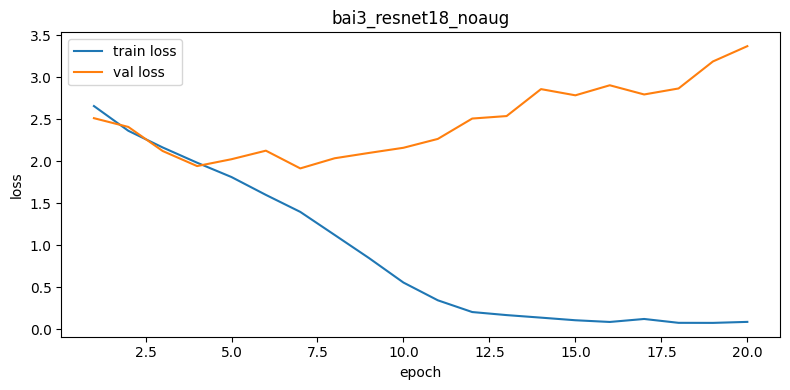

Val loss thấp nhất ở epoch 7


In [15]:
plot_history(history, run_name)


### Kết quả trên tập test


                  precision    recall  f1-score   support

        banh-can     0.2413    0.4606    0.3167       241
        banh-hoi     0.6478    0.3394    0.4454       607
    banh-mi-chao     0.4527    0.3149    0.3714       289
        banh-tet     0.6568    0.3049    0.4165       364
 banh-trang-tron     0.2671    0.2395    0.2526       309
          banh-u     0.3804    0.3977    0.3889       176
        banh-uot     0.3567    0.4446    0.3959       560
       bap-nuong     0.2830    0.1049    0.1531       143
          bo-kho     0.5171    0.3580    0.4231       338
       bo-la-lot     0.6684    0.5502    0.6036       458
       bot-chien     0.3273    0.2609    0.2903       276
           ca-ri     0.2787    0.0994    0.1466       171
    canh-kho-qua     0.4559    0.7483    0.5666       290
   canh-khoai-mo     0.8500    0.6869    0.7598       198
        ga-nuong     0.3582    0.5027    0.4183       372
          goi-ga     0.4545    0.2241    0.3002       290
          ha-

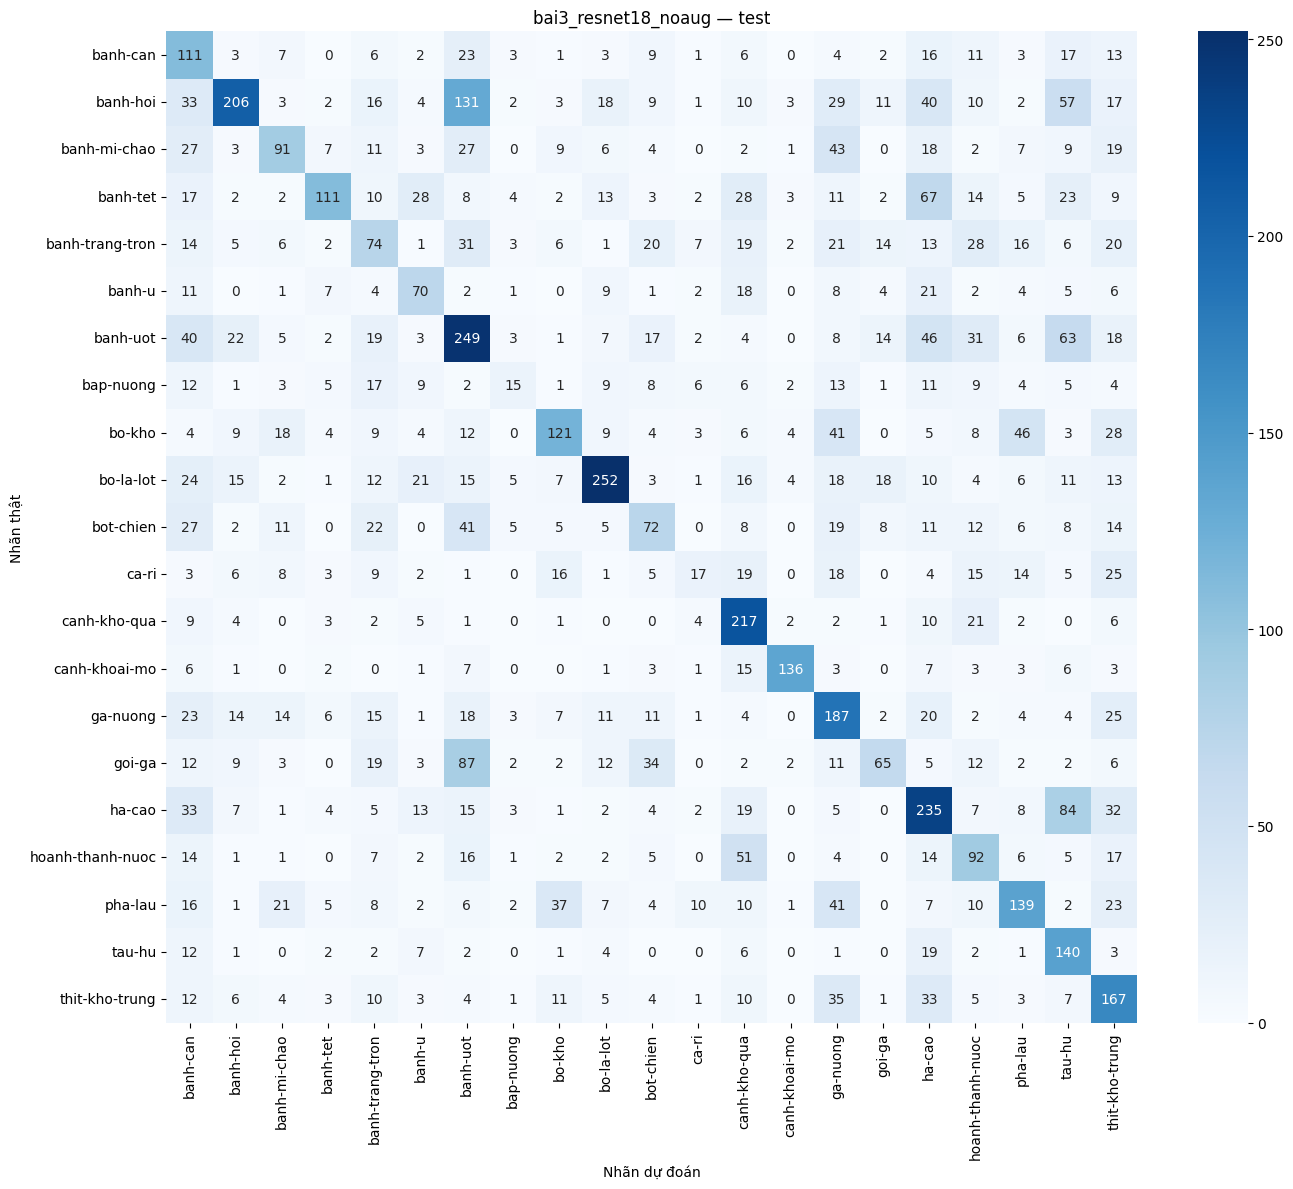

,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai3_resnet18_noaug,96,11187285,11187285,127.99847,3.499945,0.414098,0.430047,0.405157,0.395111


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

In [16]:
metrics = test_report(model, test_dl, history, run_name, config)
del model, optimizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


### Nhận xét — ResNet-18 không augmentation

Hai đường loss tách rõ từ khoảng epoch 5. Validation loss thấp nhất ở epoch 7 (1,9170), sau đó nhìn chung tăng trong khi train loss tiếp tục giảm. Đây là dấu hiệu overfitting. Checkpoint đánh giá test là epoch 16 theo validation macro-F1, đạt test accuracy 41,41% và macro-F1 39,51%.


## 3.5. ResNet-18 có augmentation


In [17]:
set_seed()
config = dict(architecture="ResNet18", img_size=96, augmentation=True, lr=1e-3, seed=SEED)
run_name = "bai3_resnet18_aug"
train_dl, val_dl, test_dl = make_loaders(96, augment=True)
model = ResNet18(num_classes=len(CLASSES)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(run_name, "| tham số:", n_params(model))


Ảnh: train=9040, val=1004, test=6682 | resize=96 | augment=True
bai3_resnet18_aug | tham số: 11187285


### Huấn luyện


In [18]:
history = fit(model, train_dl, val_dl, optimizer, run_name, config)


epoch  1 train 2.7381/0.1796 val 2.5464/0.2271 macro-F1 0.1877 99.8s *
epoch  2 train 2.4689/0.2441 val 2.4438/0.2649 macro-F1 0.2011 100.1s *
epoch  3 train 2.3189/0.2886 val 2.3163/0.2799 macro-F1 0.2408 98.7s *
epoch  4 train 2.1915/0.3251 val 2.3358/0.2809 macro-F1 0.2513 99.9s *
epoch  5 train 2.0867/0.3506 val 2.1078/0.3536 macro-F1 0.3282 99.8s *
epoch  6 train 1.9910/0.3787 val 2.0967/0.3436 macro-F1 0.3171 98.4s
epoch  7 train 1.9058/0.4061 val 1.9770/0.3894 macro-F1 0.3529 99.7s *
epoch  8 train 1.8098/0.4348 val 1.8168/0.4522 macro-F1 0.4257 99.1s *
epoch  9 train 1.7472/0.4530 val 1.8276/0.4243 macro-F1 0.4025 99.1s
epoch 10 train 1.6599/0.4698 val 1.8285/0.4343 macro-F1 0.4242 99.6s
epoch 11 train 1.5961/0.4912 val 1.7726/0.4502 macro-F1 0.4364 99.7s *
epoch 12 train 1.5256/0.5185 val 1.7559/0.4721 macro-F1 0.4723 99.4s *
epoch 13 train 1.4815/0.5322 val 1.6720/0.4741 macro-F1 0.4701 98.6s
epoch 14 train 1.4081/0.5517 val 1.5933/0.5020 macro-F1 0.4886 99.8s *
epoch 15 trai

Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

### Đường loss


,epoch,train_loss,val_loss,train_acc,val_acc,val_f1,seconds
0,1,2.738075,2.546365,0.179646,0.227092,0.187657,99.829589
1,2,2.468898,2.443772,0.244137,0.264940,0.201052,100.084790
2,3,2.318908,2.316340,0.288606,0.279880,0.240799,98.671941
3,4,2.191497,2.335784,0.325111,0.280876,0.251313,99.913022
4,5,2.086743,2.107768,0.350553,0.353586,0.328204,99.823360
5,6,1.990995,2.096721,0.378650,0.343625,0.317105,98.388288
6,7,1.905809,1.977032,0.406084,0.389442,0.352907,99.699985
7,8,1.809802,1.816846,0.434845,0.452191,0.425666,99.061331
8,9,1.747232,1.827583,0.452987,0.424303,0.402480,99.141999
9,10,1.659892,1.828459,0.469801,0.434263,0.424242,99.588776


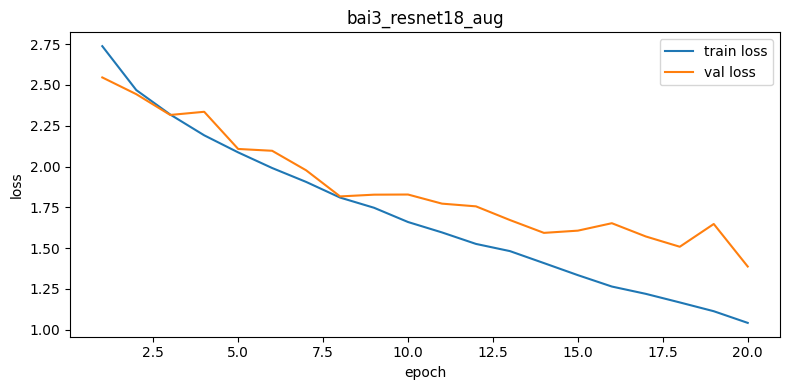

Val loss thấp nhất ở epoch 20


In [19]:
plot_history(history, run_name)


### Kết quả trên tập test


                  precision    recall  f1-score   support

        banh-can     0.3434    0.5187    0.4132       241
        banh-hoi     0.5860    0.6343    0.6092       607
    banh-mi-chao     0.5552    0.5917    0.5729       289
        banh-tet     0.6469    0.5687    0.6053       364
 banh-trang-tron     0.4207    0.2233    0.2918       309
          banh-u     0.3146    0.6364    0.4211       176
        banh-uot     0.5592    0.3625    0.4399       560
       bap-nuong     0.4184    0.2867    0.3402       143
          bo-kho     0.4347    0.5710    0.4936       338
       bo-la-lot     0.7110    0.6659    0.6877       458
       bot-chien     0.4745    0.5399    0.5051       276
           ca-ri     0.3451    0.2865    0.3131       171
    canh-kho-qua     0.6290    0.5379    0.5799       290
   canh-khoai-mo     0.9187    0.7424    0.8212       198
        ga-nuong     0.4301    0.4301    0.4301       372
          goi-ga     0.4716    0.4862    0.4788       290
          ha-

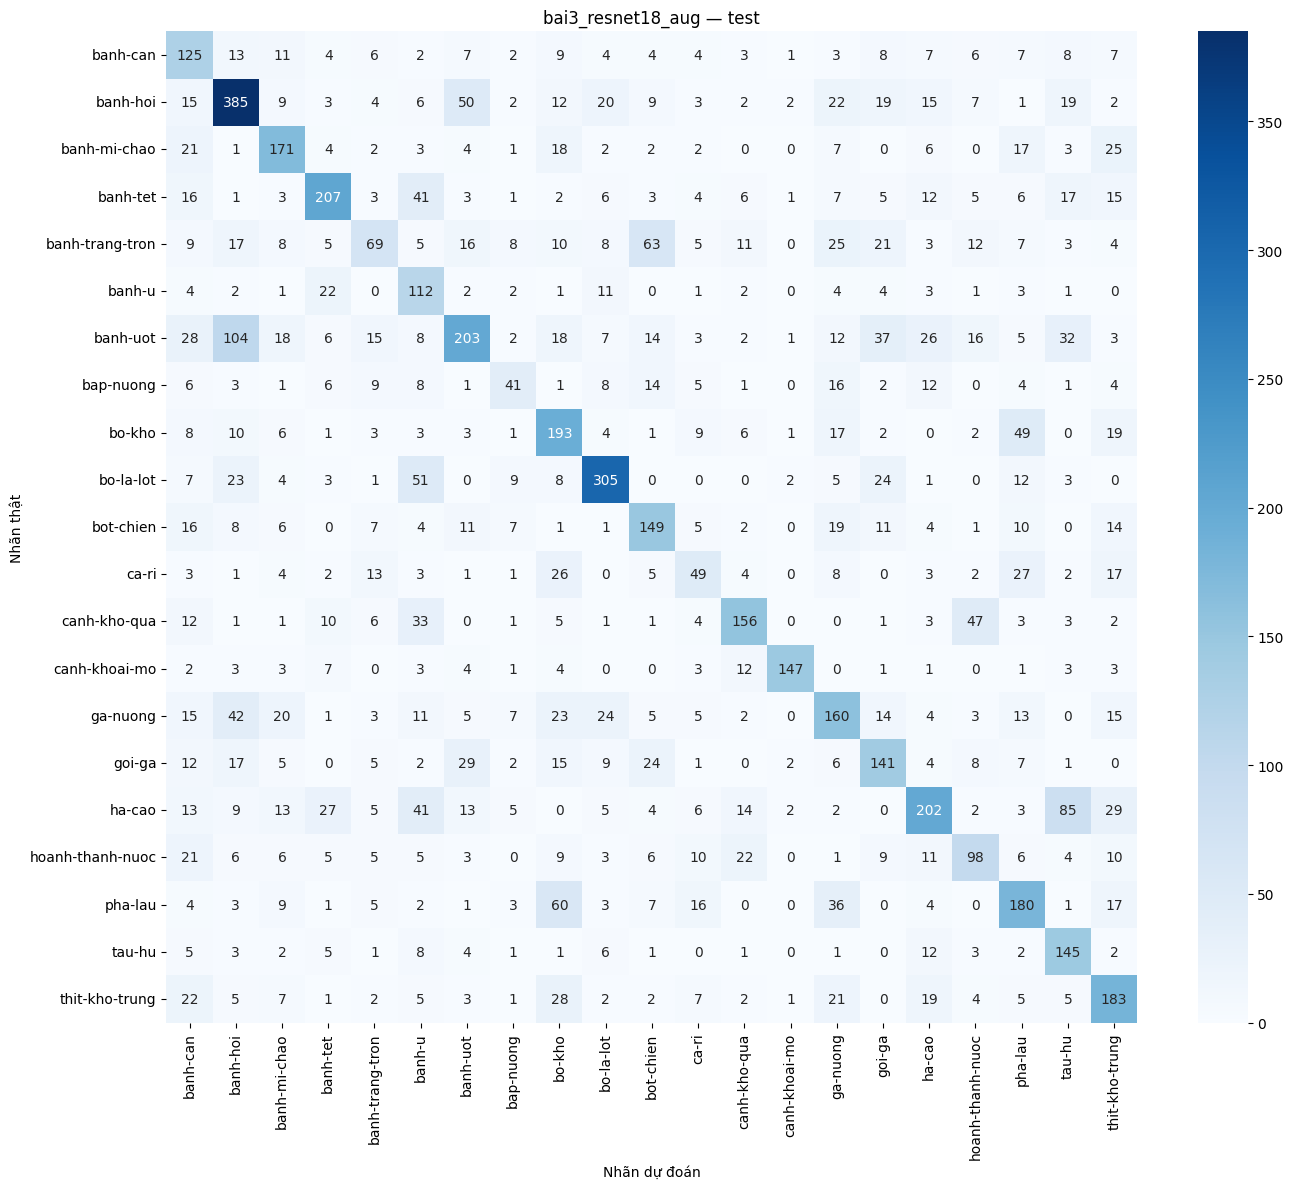

,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai3_resnet18_aug,96,11187285,11187285,99.414144,1.674825,0.511972,0.509453,0.509529,0.499112


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

In [20]:
metrics = test_report(model, test_dl, history, run_name, config)
del model, optimizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


### Nhận xét — ResNet-18 có augmentation

Từ khoảng epoch 10, khoảng cách train loss và validation loss rõ hơn, nhưng validation loss vẫn giảm về 1,3870 ở epoch 20. Chưa có xu hướng tăng kéo dài như bản không augmentation. Test accuracy đạt 51,20% và macro-F1 49,91%; macro-F1 tăng 10,40 điểm phần trăm so với không augmentation.


## 3.6. So sánh ảnh hưởng của augmentation


In [21]:
comparison3 = pd.DataFrame([RESULTS[k] for k in ["bai3_resnet18_noaug", "bai3_resnet18_aug"]])
display(comparison3)
delta3 = RESULTS["bai3_resnet18_aug"]["f1_macro"] - RESULTS["bai3_resnet18_noaug"]["f1_macro"]
print(f"Chênh lệch test macro-F1 (có − không augmentation): {delta3*100:.2f} điểm phần trăm")
comparison3.to_csv(OUT_ROOT/"comparison_bai3.csv", index=False)


,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai3_resnet18_noaug,96,11187285,11187285,127.998470,3.499945,0.414098,0.430047,0.405157,0.395111
1,bai3_resnet18_aug,96,11187285,11187285,99.414144,1.674825,0.511972,0.509453,0.509529,0.499112


Chênh lệch test macro-F1 (có − không augmentation): 10.40 điểm phần trăm


# Bài 4. ResNet-50 pretrained

Sử dụng `microsoft/resnet-50`, thay classifier bằng Linear(2048, 21). Ảnh 224×224, chuẩn hóa ImageNet. Hai thí nghiệm bắt đầu độc lập từ pretrained weights và dùng cùng augmentation.


## 4.1. Model và thông số chuẩn hóa


In [22]:
from transformers import ResNetForImageClassification, AutoImageProcessor
processor = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
print("Mean:", processor.image_mean)
print("Std:", processor.image_std)
assert np.allclose(processor.image_mean, MEAN)
assert np.allclose(processor.image_std, STD)


Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

## 4.2. Backbone và classifier

Feature extraction đóng băng backbone, bao gồm thống kê BatchNorm. Fine-tuning cập nhật toàn bộ mô hình.


In [23]:
class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for p in self.resnet.parameters():
                p.requires_grad = False

    def forward(self, images):
        features = self.resnet(images).pooler_output
        features = features.squeeze(-1).squeeze(-1)
        return self.classifier(features)

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.resnet.eval()
        return self



## 4.3. Feature extraction

Adam lr=1e-3. Tổng tham số: 23.551.061; tham số được cập nhật: 43.029.


In [24]:
set_seed()
config = dict(architecture="microsoft/resnet-50", img_size=224, augmentation=True,
              freeze_backbone=True, lr=1e-3, seed=SEED)
run_name = "bai4_resnet50_feature"
train_dl, val_dl, test_dl = make_loaders(224, augment=True)
model = PretrainedResnet(len(CLASSES), freeze_backbone=True).to(device)
assert n_params(model) == 23_551_061
assert n_params(model, True) == 43029
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
model.eval()
with torch.no_grad():
    assert model(torch.zeros(2, 3, 224, 224, device=device)).shape == (2, 21)
print("Tổng:", n_params(model), "| được cập nhật:", n_params(model, True))


Ảnh: train=9040, val=1004, test=6682 | resize=224 | augment=True
Tổng: 23551061 | được cập nhật: 43029


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

### Huấn luyện


In [25]:
history = fit(model, train_dl, val_dl, optimizer, run_name, config)


epoch  1 train 2.1030/0.4665 val 1.5738/0.6155 macro-F1 0.6170 117.7s *
epoch  2 train 1.3799/0.6548 val 1.2328/0.6663 macro-F1 0.6678 118.5s *
epoch  3 train 1.1313/0.7067 val 1.0635/0.7082 macro-F1 0.7128 118.6s *
epoch  4 train 0.9891/0.7340 val 0.9783/0.7181 macro-F1 0.7225 116.9s *
epoch  5 train 0.9096/0.7479 val 0.9239/0.7231 macro-F1 0.7361 117.2s *
epoch  6 train 0.8458/0.7654 val 0.8587/0.7460 macro-F1 0.7536 117.1s *
epoch  7 train 0.7887/0.7785 val 0.8262/0.7450 macro-F1 0.7584 116.6s *
epoch  8 train 0.7472/0.7917 val 0.7935/0.7550 macro-F1 0.7621 116.6s *
epoch  9 train 0.7213/0.7983 val 0.7826/0.7620 macro-F1 0.7676 119.4s *
epoch 10 train 0.6790/0.8080 val 0.7493/0.7620 macro-F1 0.7670 118.9s
epoch 11 train 0.6576/0.8162 val 0.7334/0.7590 macro-F1 0.7682 118.0s *
epoch 12 train 0.6398/0.8180 val 0.7145/0.7749 macro-F1 0.7838 117.7s *
epoch 13 train 0.6103/0.8288 val 0.7043/0.7620 macro-F1 0.7729 114.9s
epoch 14 train 0.5975/0.8279 val 0.6990/0.7659 macro-F1 0.7796 115.7

Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

### Đường loss


,epoch,train_loss,val_loss,train_acc,val_acc,val_f1,seconds
0,1,2.102969,1.573768,0.466482,0.615538,0.617025,117.676064
1,2,1.379861,1.232812,0.654757,0.666335,0.667754,118.498760
2,3,1.131328,1.063535,0.706748,0.708167,0.712845,118.631424
3,4,0.989065,0.978335,0.733960,0.718127,0.722468,116.901499
4,5,0.909609,0.923857,0.747898,0.723108,0.736126,117.194196
5,6,0.845765,0.858686,0.765376,0.746016,0.753601,117.054130
6,7,0.788681,0.826191,0.778540,0.745020,0.758388,116.559655
7,8,0.747205,0.793491,0.791704,0.754980,0.762066,116.552528
8,9,0.721266,0.782644,0.798341,0.761952,0.767644,119.357721
9,10,0.678974,0.749253,0.807965,0.761952,0.766996,118.916121


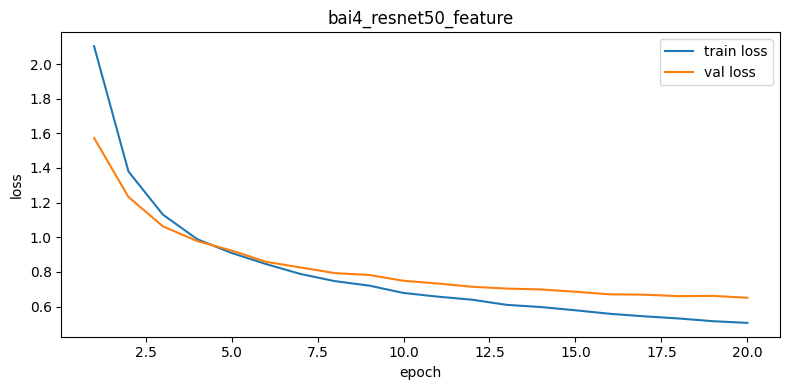

Val loss thấp nhất ở epoch 20


In [26]:
plot_history(history, run_name)


### Kết quả trên tập test


                  precision    recall  f1-score   support

        banh-can     0.7640    0.7925    0.7780       241
        banh-hoi     0.7341    0.6639    0.6972       607
    banh-mi-chao     0.8231    0.8374    0.8302       289
        banh-tet     0.9618    0.6923    0.8051       364
 banh-trang-tron     0.8745    0.6764    0.7628       309
          banh-u     0.7438    0.8580    0.7968       176
        banh-uot     0.5844    0.6554    0.6178       560
       bap-nuong     0.9392    0.9720    0.9553       143
          bo-kho     0.6187    0.7249    0.6676       338
       bo-la-lot     0.7857    0.8406    0.8122       458
       bot-chien     0.6953    0.7029    0.6991       276
           ca-ri     0.5824    0.3099    0.4046       171
    canh-kho-qua     0.7568    0.8586    0.8045       290
   canh-khoai-mo     0.8663    0.8838    0.8750       198
        ga-nuong     0.8117    0.7070    0.7557       372
          goi-ga     0.6301    0.6345    0.6323       290
          ha-

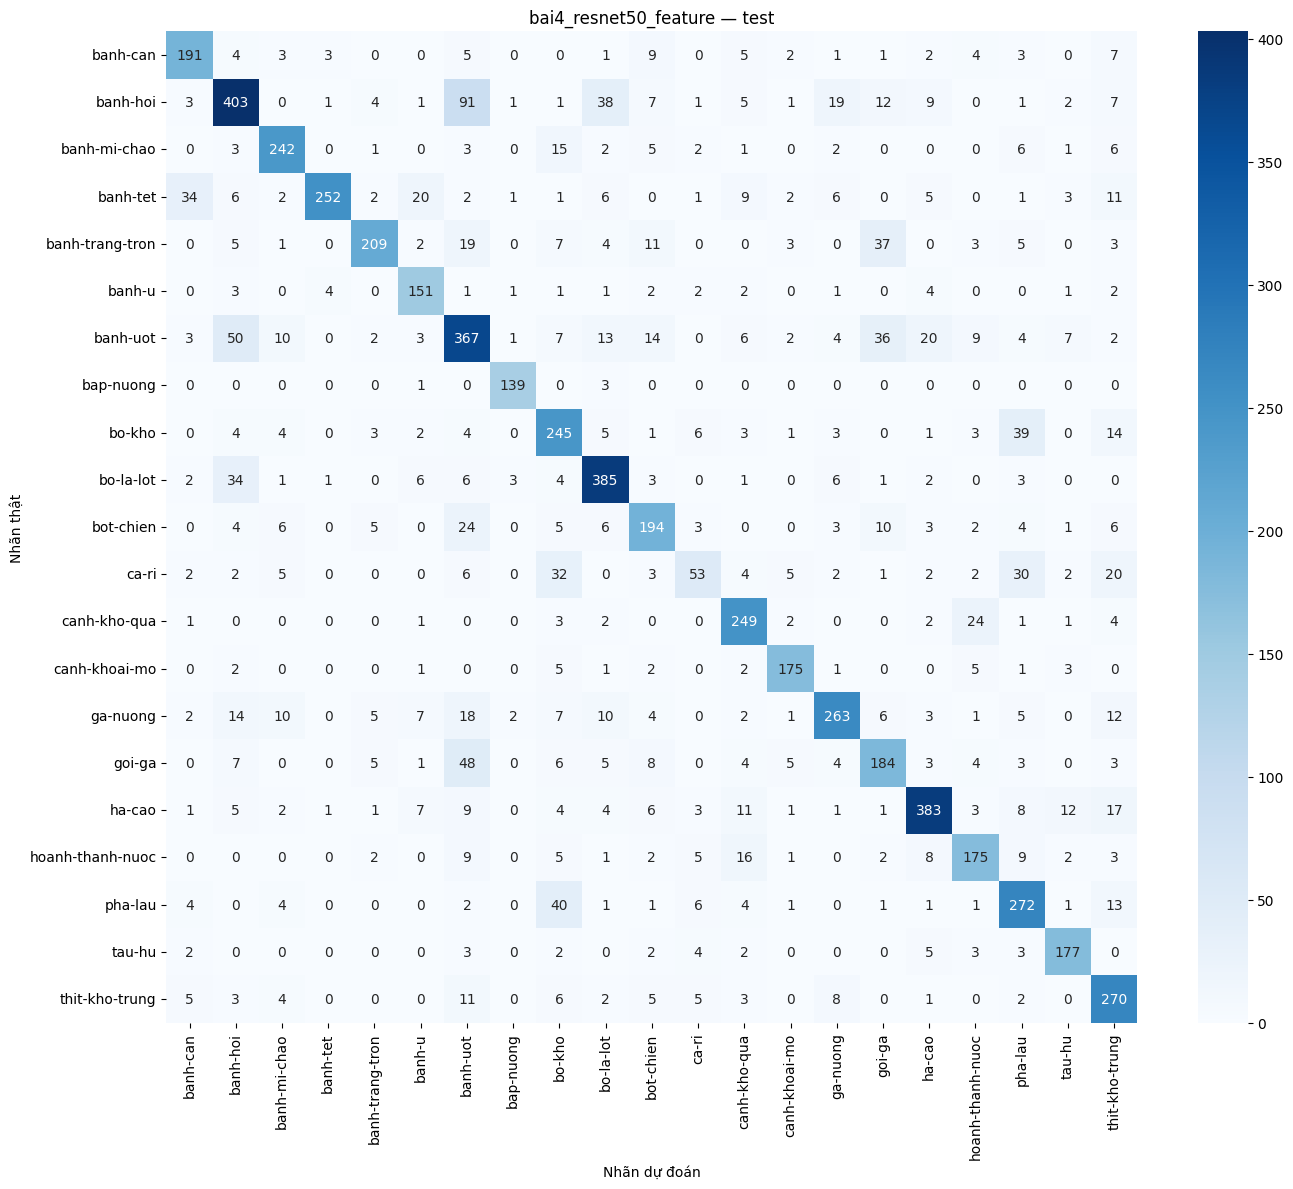

,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai4_resnet50_feature,224,23551061,43029,117.425467,0.81961,0.745136,0.758759,0.75298,0.750685


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

In [27]:
metrics = test_report(model, test_dl, history, run_name, config)
del model, optimizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


### Nhận xét — Feature extraction

Chỉ cập nhật 43.029 tham số của classifier. Validation loss giảm từ 1,5738 xuống 0,6511 sau 20 epoch. Checkpoint được chọn ở epoch 17 theo validation macro-F1; test accuracy đạt 74,51% và macro-F1 75,07%.


## 4.4. Fine-tuning

Adam lr=1e-4. Cập nhật toàn bộ 23.551.061 tham số.


In [28]:
set_seed()
config = dict(architecture="microsoft/resnet-50", img_size=224, augmentation=True,
              freeze_backbone=False, lr=1e-4, seed=SEED)
run_name = "bai4_resnet50_finetune"
train_dl, val_dl, test_dl = make_loaders(224, augment=True)
model = PretrainedResnet(len(CLASSES), freeze_backbone=False).to(device)
assert n_params(model) == 23_551_061
assert n_params(model, True) == 23551061
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)
model.eval()
with torch.no_grad():
    assert model(torch.zeros(2, 3, 224, 224, device=device)).shape == (2, 21)
print("Tổng:", n_params(model), "| được cập nhật:", n_params(model, True))


Ảnh: train=9040, val=1004, test=6682 | resize=224 | augment=True
Tổng: 23551061 | được cập nhật: 23551061


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

### Huấn luyện


In [29]:
history = fit(model, train_dl, val_dl, optimizer, run_name, config)


epoch  1 train 2.7325/0.1969 val 2.2464/0.4143 macro-F1 0.3190 126.4s *
epoch  2 train 1.6177/0.5762 val 1.0140/0.7191 macro-F1 0.6944 126.4s *
epoch  3 train 0.9160/0.7390 val 0.6777/0.7988 macro-F1 0.7878 126.5s *
epoch  4 train 0.6709/0.7927 val 0.5882/0.8187 macro-F1 0.8061 126.7s *
epoch  5 train 0.5317/0.8343 val 0.4957/0.8396 macro-F1 0.8340 126.9s *
epoch  6 train 0.4432/0.8618 val 0.4712/0.8456 macro-F1 0.8401 125.3s *
epoch  7 train 0.3762/0.8820 val 0.4448/0.8635 macro-F1 0.8623 127.4s *
epoch  8 train 0.3117/0.9029 val 0.4229/0.8665 macro-F1 0.8613 125.9s
epoch  9 train 0.2836/0.9102 val 0.4082/0.8755 macro-F1 0.8686 125.7s *
epoch 10 train 0.2319/0.9283 val 0.4085/0.8715 macro-F1 0.8657 126.5s
epoch 11 train 0.2122/0.9361 val 0.3836/0.8855 macro-F1 0.8819 127.5s *
epoch 12 train 0.1765/0.9483 val 0.4005/0.8865 macro-F1 0.8831 128.6s *
epoch 13 train 0.1509/0.9555 val 0.3946/0.8835 macro-F1 0.8791 127.6s
epoch 14 train 0.1328/0.9608 val 0.3848/0.8825 macro-F1 0.8803 128.3s


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

### Đường loss


,epoch,train_loss,val_loss,train_acc,val_acc,val_f1,seconds
0,1,2.732531,2.246409,0.196903,0.414343,0.318973,126.425167
1,2,1.617744,1.013963,0.576217,0.719124,0.694412,126.381590
2,3,0.916049,0.677721,0.739049,0.798805,0.787791,126.525450
3,4,0.670852,0.588249,0.792699,0.818725,0.806073,126.688344
4,5,0.531692,0.495651,0.834292,0.839641,0.834026,126.916100
5,6,0.443225,0.471242,0.861836,0.845618,0.840098,125.280798
6,7,0.376154,0.444816,0.881969,0.863546,0.862328,127.351301
7,8,0.311689,0.422889,0.902876,0.866534,0.861266,125.908441
8,9,0.283602,0.408229,0.910177,0.875498,0.868571,125.741600
9,10,0.231937,0.408505,0.928319,0.871514,0.865745,126.485694


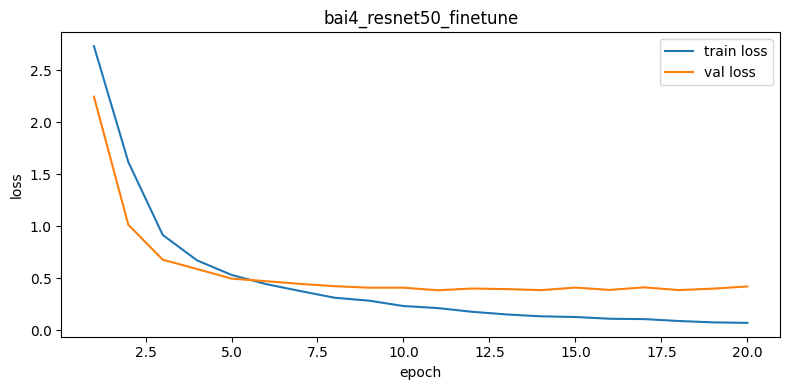

Val loss thấp nhất ở epoch 11


In [30]:
plot_history(history, run_name)


### Kết quả trên tập test


                  precision    recall  f1-score   support

        banh-can     0.8421    0.9295    0.8836       241
        banh-hoi     0.8835    0.8748    0.8791       607
    banh-mi-chao     0.9212    0.9308    0.9260       289
        banh-tet     0.9790    0.7692    0.8615       364
 banh-trang-tron     0.9189    0.8803    0.8992       309
          banh-u     0.8610    0.9148    0.8871       176
        banh-uot     0.8339    0.8250    0.8294       560
       bap-nuong     0.9329    0.9720    0.9521       143
          bo-kho     0.8586    0.7722    0.8131       338
       bo-la-lot     0.8613    0.9629    0.9093       458
       bot-chien     0.8262    0.8442    0.8351       276
           ca-ri     0.6250    0.6433    0.6340       171
    canh-kho-qua     0.9577    0.9379    0.9477       290
   canh-khoai-mo     0.9632    0.9242    0.9433       198
        ga-nuong     0.8707    0.7419    0.8012       372
          goi-ga     0.8000    0.8138    0.8068       290
          ha-

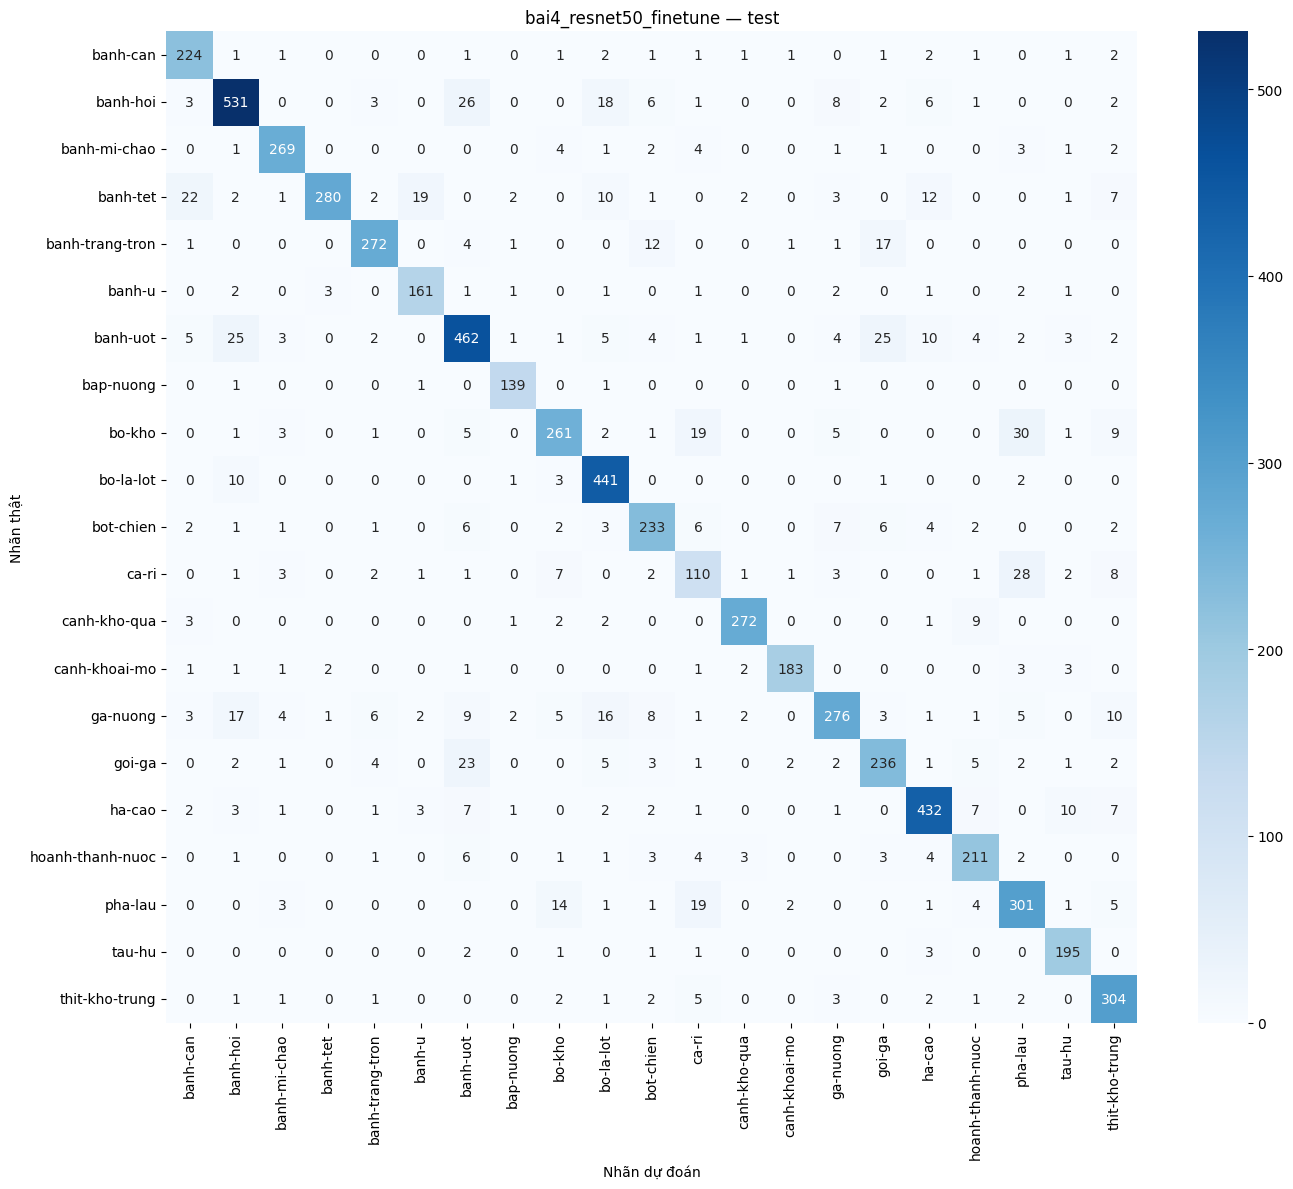

,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai4_resnet50_finetune,224,23551061,23551061,127.107909,0.503631,0.866956,0.866839,0.869859,0.866773


Nhật ký cảnh báo và tiến độ được thu gọn trong phần HTML.

In [31]:
metrics = test_report(model, test_dl, history, run_name, config)
del model, optimizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


### Nhận xét — Fine-tuning

Cập nhật toàn bộ 23.551.061 tham số với lr=1e-4. Validation loss thấp nhất ở epoch 11 (0,3836); sau đó train loss tiếp tục giảm nhưng validation loss dao động cao hơn mức này, có dấu hiệu quá khớp xét theo loss. Checkpoint được chọn ở epoch 19 theo validation macro-F1, đạt test accuracy 86,70% và macro-F1 86,68%. Macro-F1 cao hơn feature extraction 11,61 điểm phần trăm.


## 4.5. So sánh feature extraction và fine-tuning


In [32]:
comparison4 = pd.DataFrame([RESULTS[k] for k in ["bai4_resnet50_feature", "bai4_resnet50_finetune"]])
display(comparison4)
delta4 = RESULTS["bai4_resnet50_finetune"]["f1_macro"] - RESULTS["bai4_resnet50_feature"]["f1_macro"]
print(f"Chênh lệch test macro-F1 (fine-tune − feature extraction): {delta4*100:.2f} điểm phần trăm")
comparison4.to_csv(OUT_ROOT/"comparison_bai4.csv", index=False)


,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai4_resnet50_feature,224,23551061,43029,117.425467,0.819610,0.745136,0.758759,0.752980,0.750685
1,bai4_resnet50_finetune,224,23551061,23551061,127.107909,0.503631,0.866956,0.866839,0.869859,0.866773


Chênh lệch test macro-F1 (fine-tune − feature extraction): 11.61 điểm phần trăm


## Tổng hợp kết quả Bài 3 và Bài 4


In [33]:
summary = pd.DataFrame(RESULTS.values())
display(summary)
summary.to_csv(OUT_ROOT/"summary_bai3_bai4.csv", index=False)


,run,resize,params,trainable_params,seconds_per_epoch,test_loss,accuracy,precision_macro,recall_macro,f1_macro
0,bai3_resnet18_noaug,96,11187285,11187285,127.998470,3.499945,0.414098,0.430047,0.405157,0.395111
1,bai3_resnet18_aug,96,11187285,11187285,99.414144,1.674825,0.511972,0.509453,0.509529,0.499112
2,bai4_resnet50_feature,224,23551061,43029,117.425467,0.819610,0.745136,0.758759,0.752980,0.750685
3,bai4_resnet50_finetune,224,23551061,23551061,127.107909,0.503631,0.866956,0.866839,0.869859,0.866773


## Nhận xét chung

Augmentation giúp ResNet-18 tăng test macro-F1 từ 39,51% lên 49,91% và giảm mức quá khớp thấy ở bản không augmentation. Với ResNet-50, fine-tuning tốt hơn việc chỉ học classifier trong lần chạy này.

ResNet-50 fine-tuning cao hơn ResNet-18 có augmentation 35,50 điểm phần trăm accuracy và 36,77 điểm phần trăm macro-F1 trên test. Trọng số ImageNet là một lợi thế khi học từ bộ dữ liệu này. Tuy nhiên, hai thí nghiệm còn khác kiến trúc và kích thước ảnh (224×224 so với 96×96), nên không thể quy toàn bộ chênh lệch cho pretraining.


## Bảng tổng hợp kết quả

Bảng sử dụng LeNet AvgPool, GoogLeNet rút gọn, ResNet-18 có augmentation và ResNet-50 fine-tuning. Kết quả đều tính trên test; hai bảng so sánh phía trên giữ đủ các biến thể của Bài 3–4.

**Cách đo thời gian:** LeNet/GoogLeNet đo bổ sung một epoch train + validation trên CPU. ResNet lấy trung bình 20 epoch train + validation trên Tesla T4. Các số này mô tả những lần chạy khác phần cứng và cách lấy trung bình, không dùng để so tốc độ trực tiếp giữa CPU và GPU.


In [ ]:
# Kết quả Bài 1–2 từ assignments.ipynb.
ket_qua_bai12 = pd.DataFrame([
    {
        "Mô hình": "LeNet-5 điều chỉnh",
        "Resize": "64×64",
        "Tham số": 339421,
        "Giây/epoch": 127.58827970002312,
        "Accuracy": 0.3033522897336126,
        "macro-F1": 0.2786080029711096
    },
    {
        "Mô hình": "GoogLeNet rút gọn",
        "Resize": "64×64",
        "Tham số": 78389,
        "Giây/epoch": 145.37829210003838,
        "Accuracy": 0.3651601316970966,
        "macro-F1": 0.341360243780897
    }
])

bang_tong_hop_4 = pd.concat([
    ket_qua_bai12,
    pd.DataFrame([
        {
            "Mô hình": "ResNet-18 từ đầu",
            "Resize": "96×96",
            "Tham số": RESULTS["bai3_resnet18_aug"]["params"],
            "Giây/epoch": RESULTS["bai3_resnet18_aug"]["seconds_per_epoch"],
            "Accuracy": RESULTS["bai3_resnet18_aug"]["accuracy"],
            "macro-F1": RESULTS["bai3_resnet18_aug"]["f1_macro"],
        },
        {
            "Mô hình": "ResNet-50 pretrained",
            "Resize": "224×224",
            "Tham số": RESULTS["bai4_resnet50_finetune"]["params"],
            "Giây/epoch": RESULTS["bai4_resnet50_finetune"]["seconds_per_epoch"],
            "Accuracy": RESULTS["bai4_resnet50_finetune"]["accuracy"],
            "macro-F1": RESULTS["bai4_resnet50_finetune"]["f1_macro"],
        },
    ]),
], ignore_index=True)

bang_tong_hop_4.to_csv(OUT_ROOT/"summary_all4_models.csv", index=False)
bang_hien_thi = bang_tong_hop_4.copy()
bang_hien_thi["Tham số"] = bang_hien_thi["Tham số"].map("{:,}".format)
bang_hien_thi["Giây/epoch"] = bang_hien_thi["Giây/epoch"].map("{:.2f}".format)
for column in ["Accuracy", "macro-F1"]:
    bang_hien_thi[column] = bang_hien_thi[column].map("{:.2%}".format)
display(bang_hien_thi)


Mô hình,Resize,Tham số,Giây/epoch,Accuracy,macro-F1
LeNet-5 điều chỉnh,64×64,"339,421",127.59,30.34%,27.86%
GoogLeNet rút gọn,64×64,"78,389",145.38,36.52%,34.14%
ResNet-18 từ đầu,96×96,"11,187,285",99.41,51.20%,49.91%
ResNet-50 pretrained,224×224,"23,551,061",127.11,86.70%,86.68%
